# HomeWork -4
## Objective
 In this homework, you will design a python class that encapsulates common univariate/bivariate analysis tasks. You will practice object oriented programing (OOP) while applying descriptive statistics and visualization to summarize your data and explore the relationship between two variables. 
 
 - Use the example provided in the class activity and expand it. The initializer of the class should take data and print out its shape and column names. 
 - Additionally, your class should include at least 5 methods (function) to do either univariate or bivariate analysis of your choice. 
 - Provide markdowns or comments for each part of your code.  

  - Create an instance of your class using Penguin data and use it to analyze it.
  
  - For each analysis you perform, write 1-2 sentence before that function call that clearly state
    the question you are trying to answer with that analysis. For example: "In this analysis I want to see what is the average mass for each species." 

  


=== Dataset Initialized ===
Dataset Shape: 344 rows, 7 columns
Column Names: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']



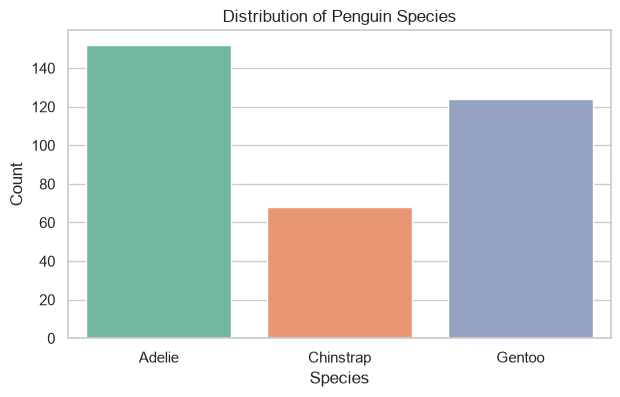

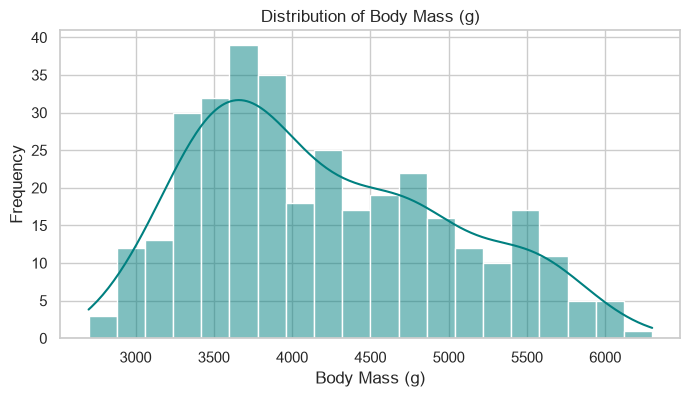

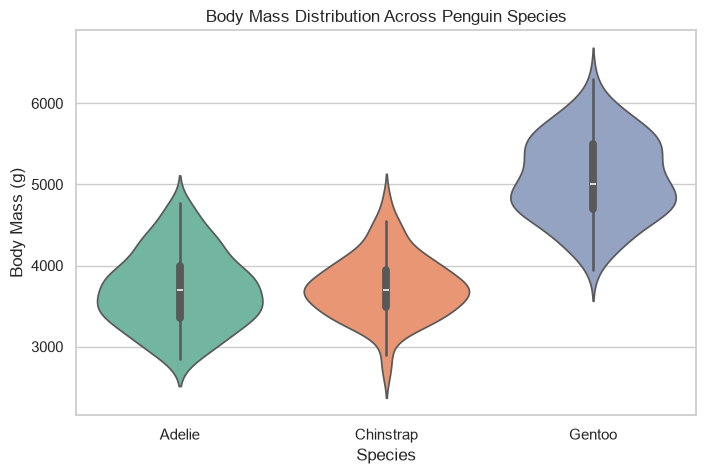

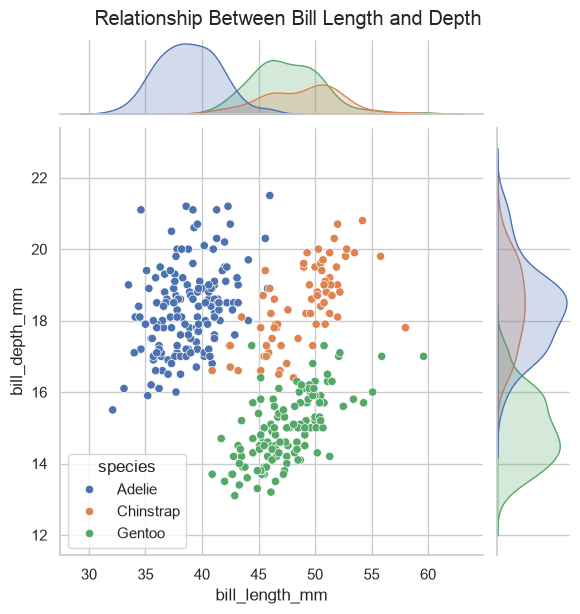

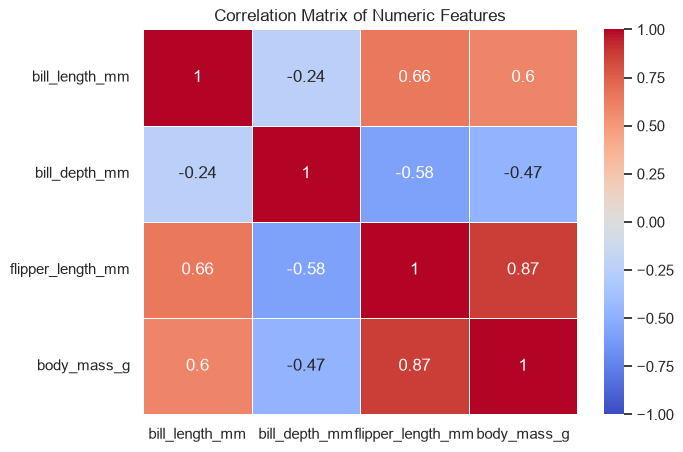

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set overall theme for Seaborn visualizations
sns.set_theme(style="whitegrid")


class PenguinAnalyzer:
    """A class to encapsulate univariate and bivariate analysis tasks for dataset exploration."""

    def __init__(self, data):
        """Initializer that accepts dataset and prints shape and column names."""
        self.df = data
        print("=== Dataset Initialized ===")
        print(f"Dataset Shape: {self.df.shape[0]} rows, {self.df.shape[1]} columns")
        print(f"Column Names: {list(self.df.columns)}\n")

    # Method 1: Univariate Categorical Analysis
    def plot_species_distribution(self):
        """Univariate analysis showing count distribution of penguin species."""
        plt.figure(figsize=(7, 4))
        sns.countplot(
            data=self.df, x="species", hue="species", legend=False, palette="Set2"
        )
        plt.title("Distribution of Penguin Species")
        plt.xlabel("Species")
        plt.ylabel("Count")
        plt.show()

    # Method 2: Univariate Numerical Analysis
    def plot_bodymass_distribution(self):
        """Univariate analysis showing body mass distribution via histogram and KDE."""
        plt.figure(figsize=(8, 4))
        sns.histplot(
            data=self.df, x="body_mass_g", kde=True, color="teal", bins=20
        )
        plt.title("Distribution of Body Mass (g)")
        plt.xlabel("Body Mass (g)")
        plt.ylabel("Frequency")
        plt.show()

    # Method 3: Bivariate Categorical vs Numerical Analysis
    def plot_bodymass_by_species(self):
        """Bivariate analysis examining body mass across species using violin plots."""
        plt.figure(figsize=(8, 5))
        sns.violinplot(
            data=self.df,
            x="species",
            y="body_mass_g",
            hue="species",
            legend=False,
            palette="Set2",
        )
        plt.title("Body Mass Distribution Across Penguin Species")
        plt.xlabel("Species")
        plt.ylabel("Body Mass (g)")
        plt.show()

    # Method 4: Bivariate Numerical vs Numerical Analysis
    def plot_bill_dimensions_joint(self):
        """Bivariate analysis checking relationship between bill length and bill depth."""
        sns.jointplot(
            data=self.df, x="bill_length_mm", y="bill_depth_mm", hue="species"
        )
        plt.suptitle(
            "Relationship Between Bill Length and Depth", y=1.02
        )
        plt.show()

    # Method 5: Multivariate Correlation Analysis
    def plot_correlation_matrix(self):
        """Bivariate/Multivariate correlation matrix for all numeric features."""
        corr = self.df.corr(numeric_only=True)
        plt.figure(figsize=(7, 5))
        sns.heatmap(
            corr,
            annot=True,
            cmap="coolwarm",
            linewidths=0.5,
            vmin=-1,
            vmax=1,
        )
        plt.title("Correlation Matrix of Numeric Features")
        plt.show()


# Load Penguin dataset from Seaborn
penguins = sns.load_dataset("penguins")

# Instantiate class (prints shape and column names automatically)
analyzer = PenguinAnalyzer(penguins)

# --- Perform Analyses with 1-2 sentence questions before each call ---

# Analysis 1
# Question: In this analysis, I want to see how many penguins belong to each species in the dataset.
analyzer.plot_species_distribution()

# Analysis 2
# Question: In this analysis, I want to observe the overall distribution and frequency of body mass across all penguins.
analyzer.plot_bodymass_distribution()

# Analysis 3
# Question: In this analysis, I want to see if penguin species differ significantly in their body mass distribution.
analyzer.plot_bodymass_by_species()

# Analysis 4
# Question: In this analysis, I want to examine the relationship between bill length and bill depth across different species.
analyzer.plot_bill_dimensions_joint()

# Analysis 5
# Question: In this analysis, I want to determine which numerical measurements strongly correlate with each other.
analyzer.plot_correlation_matrix()